In [1]:
import pickle
import itertools
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
import arviz as az
import xarray
from scipy import stats as scipystats

import jax
import jax.numpy as jnp
from jax.scipy import stats
from jax.config import config
config.update('jax_platform_name', 'cpu')

In [2]:
plt.style.use("default")

In [3]:
try:
    # filename = str(snakemake.input)
    print(snakemake.input)
    figdir = "latex/figures/"
except NameError:
    hierarchical_posteriors_dirname = "../../../results/adult-reduced/hierarchical-downstream-posteriors/"
    real_data_results_dirname = "../../../results/adult-reduced/real-data-results/"
    figdir = "../../../latex/figures/adult-reduced/"


epsilon = 1.0
# repeat_ind = 0
n_repeats = 5
syn_data_name = "Syn. data $\\bar{p}_n(Q)$"

filename = real_data_results_dirname + "results.p"
with open(filename, "rb") as file:
    real_data_obj = pickle.load(file)

real_data_inf_data = real_data_obj["nondp_hierarchical_inf_data"]
real_data_posterior = real_data_inf_data.posterior.stack(draws=("chain", "draw"))

n_syn_datasets = 200
posterior_xarrays = {i: [] for i in range(n_repeats)}
posterior_inf_datas = {i: [] for i in range(n_repeats)}
diagnostic_records = {i: [] for i in range(n_repeats)}
syn_data_inds_with_convergence_problems = {i: [] for i in range(n_repeats)}
for repeat_ind in range(n_repeats):
    for syn_data_ind in range(n_syn_datasets):
        with open(hierarchical_posteriors_dirname + "{}_{}_{}.p".format(repeat_ind, syn_data_ind, epsilon), "rb") as file:
            downstream_posterior_object = pickle.load(file)
        downstream_inf_data = downstream_posterior_object["hierarchical_inf_data"]
        posterior_inf_datas[repeat_ind].append(downstream_inf_data)

        summary = az.summary(downstream_inf_data)

        posterior_values = downstream_inf_data.posterior.stack(draws=("chain", "draw"), create_index=False)
        posterior_xarrays[repeat_ind].append(posterior_values)

        for param in summary.index:
            diagnostic_records[repeat_ind].append({
                "Param.": param,
                "R_hat": summary.loc[param].r_hat,
                "ESS": summary.loc[param].ess_bulk,
            })
        if summary.r_hat.max() > 1.05:
            syn_data_inds_with_convergence_problems[repeat_ind].append(syn_data_ind)

diagnostic_dfs = {i: pd.DataFrame.from_records(diagnostic_record) for i, diagnostic_record in diagnostic_records.items()}

In [4]:
syn_data_inds_with_convergence_problems

{0: [13, 19, 30, 32, 39, 69, 122, 127, 162, 169, 171, 177, 189],
 1: [3, 39, 142, 143, 170, 181],
 2: [81, 83, 87, 92, 109, 163],
 3: [8, 76, 79, 80, 99, 132, 198],
 4: [29, 35, 48, 67, 159, 172, 175]}

In [54]:
{i: len(inds) for i, inds in syn_data_inds_with_convergence_problems.items()}

{0: 13, 1: 6, 2: 6, 3: 7, 4: 7}

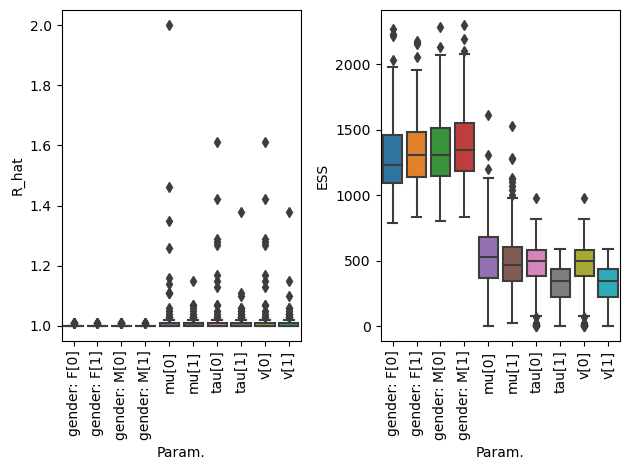

In [6]:
fig, axes = plt.subplots(1, 2)

ax = axes[0]
sns.boxplot(data=diagnostic_dfs[0], x="Param.", y="R_hat", ax=ax)
ax.tick_params("x", labelrotation=90)

ax = axes[1]
sns.boxplot(data=diagnostic_dfs[0], x="Param.", y="ESS", ax=ax)
ax.tick_params("x", labelrotation=90)

plt.tight_layout()
plt.show()

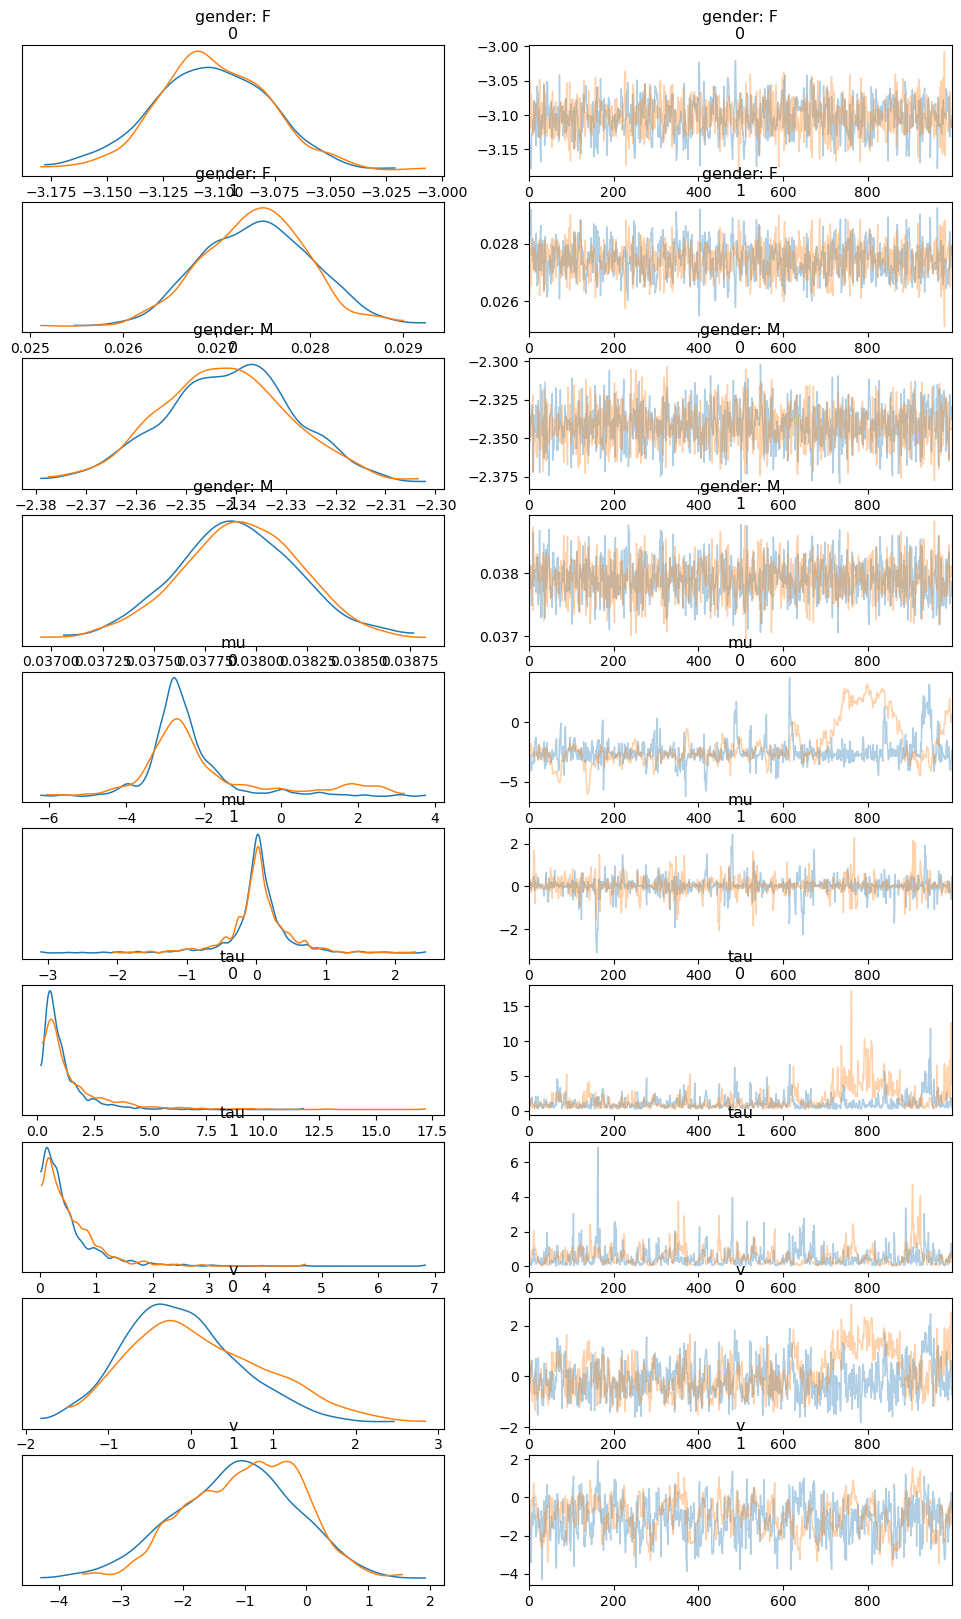

In [7]:
az.plot_trace(posterior_inf_datas[0][69], compact=False)
plt.show()

In [8]:
unstacked_posteriors = {i: xarray.concat(posterior_xarray, dim="syn_datasets") for i, posterior_xarray in posterior_xarrays.items()}
stacked_posteriors = {i: unstacked_posterior.stack(samples=("syn_datasets", "draws")) for i, unstacked_posterior in unstacked_posteriors.items()}

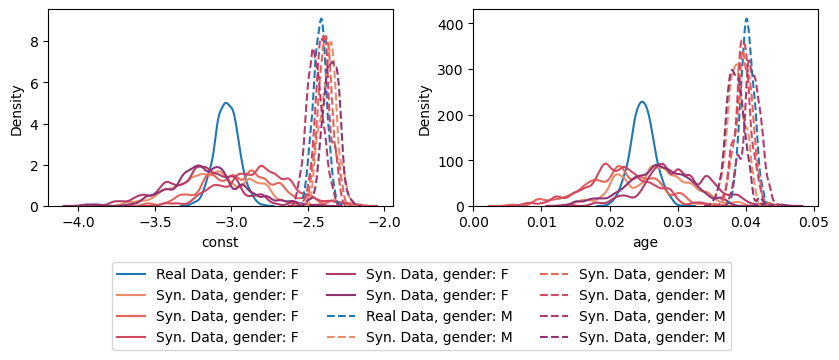

In [49]:
gender_tags = [
    "gender: F", "gender: M"
]
gender_linestyles = [
    "solid", "dashed"
]
syn_palette = sns.color_palette("flare")
coef_names = ["const", "age"]
fig, axes = plt.subplots(1, 2, figsize=(8.5, 2.7))
for gender_ind, gender_tag in enumerate(gender_tags):
    real_data_post_gender = real_data_posterior[gender_tag].values.transpose()
    for coef_ind, coef_name in enumerate(coef_names):
        ax = axes[coef_ind]
        ax.set_xlabel(coef_name)
        sns.kdeplot(
            real_data_post_gender[:, coef_ind], ax=ax, 
            color="C0", 
            linestyle=gender_linestyles[gender_ind],
            label="{}, {}".format("Real Data", gender_tag)
        )

        for i, stacked_posterior in stacked_posteriors.items():
            syn_data_post_gender = stacked_posterior[gender_tag].values.transpose()
            sns.kdeplot(
                syn_data_post_gender[:, coef_ind], ax=ax, 
                label="{}, {}".format("Syn. Data", gender_tag),
                linestyle=gender_linestyles[gender_ind],
                color=syn_palette[i],
            )
        leg_info = ax.get_legend_handles_labels()
plt.tight_layout()
plt.legend(*leg_info, loc="upper center", bbox_to_anchor=(-0.15, -0.25), ncol=3)
plt.savefig(figdir + "hierarchical_lr_age_marginals.pdf", bbox_inches="tight")
plt.show()


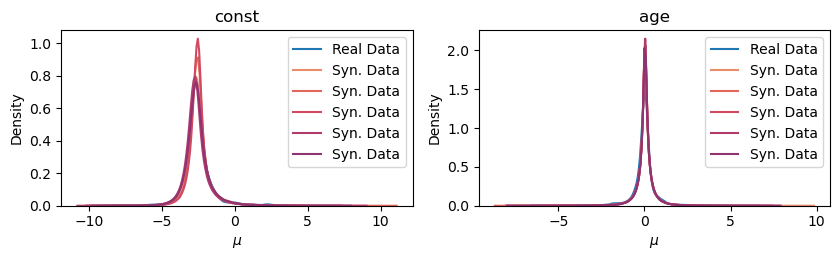

In [50]:
coef_names = ["const", "age"]
fig, axes = plt.subplots(1, 2, figsize=(8.5, 2.7))

real_data_post_mu = real_data_posterior.mu.values.transpose()
for coef_ind, coef_name in enumerate(coef_names):
    ax = axes[coef_ind]
    sns.kdeplot(real_data_post_mu[:, coef_ind], ax=ax, label="Real Data", color="C0")
    ax.set_title(coef_name)
    ax.set_xlabel("$\\mu$")
    for i, stacked_posterior in stacked_posteriors.items():
        syn_data_post_mu = stacked_posterior.mu.values.transpose()
        sns.kdeplot(syn_data_post_mu[:, coef_ind], ax=ax, label="Syn. Data", color=syn_palette[i])
    ax.legend()

plt.tight_layout()
plt.savefig(figdir + "hierarchical_lr_mu_marginals.pdf")
plt.show()


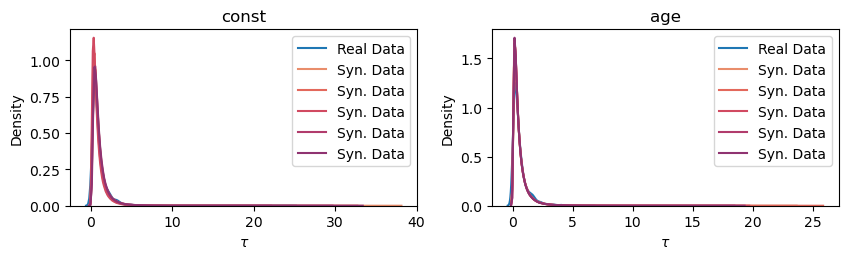

In [51]:
coef_names = ["const", "age"]
fig, axes = plt.subplots(1, 2, figsize=(8.5, 2.7))

real_data_post_tau = real_data_posterior.tau.values.transpose()
for coef_ind, coef_name in enumerate(coef_names):
    ax = axes[coef_ind]
    sns.kdeplot(real_data_post_tau[:, coef_ind], ax=ax, label="Real Data", color="C0")
    ax.set_title(coef_name)
    ax.set_xlabel("$\\tau$")
    for i, stacked_posterior in stacked_posteriors.items():
        syn_data_post_tau = stacked_posterior.tau.values.transpose()
        sns.kdeplot(syn_data_post_tau[:, coef_ind], ax=ax, label="Syn. Data", color=syn_palette[i])
    ax.legend()

plt.tight_layout()
plt.savefig(figdir + "hierarchical_lr_tau_marginals.pdf")
plt.show()

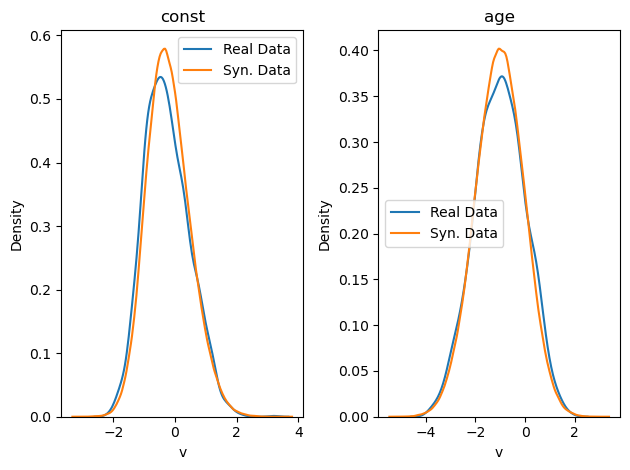

In [15]:
coef_names = ["const", "age"]
fig, axes = plt.subplots(1, 2)

real_data_post_v = real_data_posterior.v.values.transpose()
syn_data_post_v = stacked_posterior.v.values.transpose()
for coef_ind, coef_name in enumerate(coef_names):
    ax = axes[coef_ind]
    sns.kdeplot(real_data_post_v[:, coef_ind], ax=ax, label="Real Data")
    sns.kdeplot(syn_data_post_v[:, coef_ind], ax=ax, label="Syn. Data")
    ax.set_title(coef_name)
    ax.set_xlabel("v")
    ax.legend()

plt.tight_layout()
plt.show()


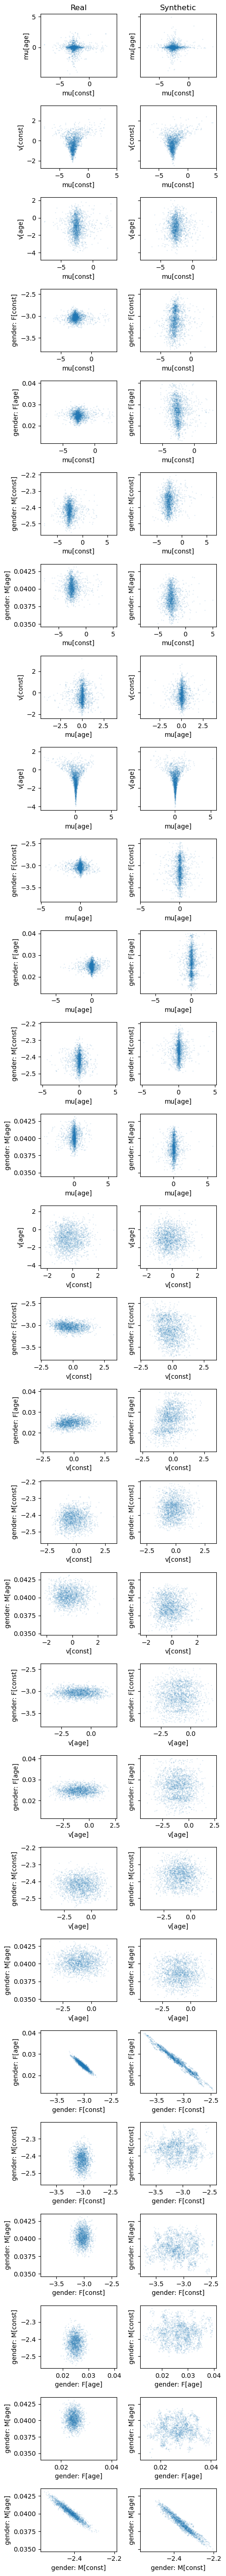

In [43]:
selected_repeat = 0
stacked_posterior = stacked_posteriors[selected_repeat]
variables = ["mu", "v", "gender: F", "gender: M"]
coef_inds = range(len(coef_names))
variable_coef_pairs = itertools.product(variables, coef_inds)
plotted_pairs = list(itertools.combinations(variable_coef_pairs, 2))

fig, axes = plt.subplots(len(plotted_pairs), 2, figsize=(2 * 2.5, len(plotted_pairs) * 2), sharex="row", sharey="row")
for i, ((var1, coef1), (var2, coef2)) in enumerate(plotted_pairs):

    real_data_post_1 = real_data_posterior[var1].values.transpose()[:, coef1]
    real_data_post_2 = real_data_posterior[var2].values.transpose()[:, coef2]

    syn_data_post_1 = stacked_posterior[var1].values.transpose()[:, coef1]
    syn_data_post_2 = stacked_posterior[var2].values.transpose()[:, coef2]
    subsample_inds = np.random.choice(syn_data_post_1.shape[0], size=real_data_post_1.shape[0], replace=False)
    syn_data_post_1 = syn_data_post_1[subsample_inds]
    syn_data_post_2 = syn_data_post_2[subsample_inds]

    ax = axes[i, 0]
    if i == 0:
        ax.set_title("Real")
    ax.scatter(real_data_post_1, real_data_post_2, s=0.2, alpha=0.2)
    ax.set_xlabel("{}[{}]".format(var1, coef_names[coef1]))
    ax.set_ylabel("{}[{}]".format(var2, coef_names[coef2]))

    ax = axes[i, 1]
    if i == 0:
        ax.set_title("Synthetic")
    ax.scatter(syn_data_post_1, syn_data_post_2, s=0.2, alpha=0.2)
    ax.set_xlabel("{}[{}]".format(var1, coef_names[coef1]))
    ax.set_ylabel("{}[{}]".format(var2, coef_names[coef2]))

plt.tight_layout()
plt.savefig(figdir + "hierarchical_lr_2_way_marginals.pdf")
plt.show()

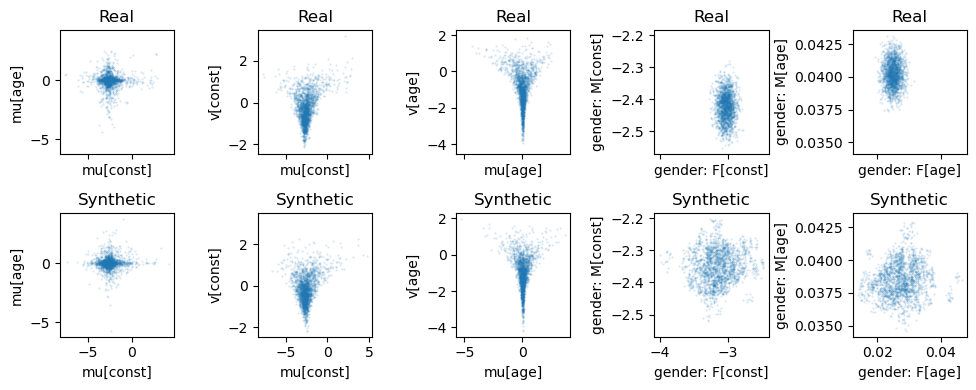

In [53]:
selected_pairs = [
    (('mu', 0), ('mu', 1)),
    (('mu', 0), ('v', 0)),
    # (('mu', 0), ('v', 1)),
    # (('mu', 0), ('gender: F', 0)),
    # (('mu', 0), ('gender: F', 1)),
    # (('mu', 0), ('gender: M', 0)),
    # (('mu', 0), ('gender: M', 1)),
    # (('mu', 1), ('v', 0)),
    (('mu', 1), ('v', 1)),
    # (('mu', 1), ('gender: F', 0)),
    # (('mu', 1), ('gender: F', 1)),
    # (('mu', 1), ('gender: M', 0)),
    # (('mu', 1), ('gender: M', 1)),
    # (('v', 0), ('v', 1)),
    # (('v', 0), ('gender: F', 0)),
    # (('v', 0), ('gender: F', 1)),
    # (('v', 0), ('gender: M', 0)),
    # (('v', 0), ('gender: M', 1)),
    # (('v', 1), ('gender: F', 0)),
    # (('v', 1), ('gender: F', 1)),
    # (('v', 1), ('gender: M', 0)),
    # (('v', 1), ('gender: M', 1)),
    # (('gender: F', 0), ('gender: F', 1)),
    (('gender: F', 0), ('gender: M', 0)),
    # (('gender: F', 0), ('gender: M', 1)),
    # (('gender: F', 1), ('gender: M', 0)),
    (('gender: F', 1), ('gender: M', 1)),
    # (('gender: M', 0), ('gender: M', 1))
]
fig, axes = plt.subplots(2, len(selected_pairs), figsize=(len(selected_pairs) * 2, 2 * 2.0), sharex="col", sharey="col")
for i, ((var1, coef1), (var2, coef2)) in enumerate(selected_pairs):

    real_data_post_1 = real_data_posterior[var1].values.transpose()[:, coef1]
    real_data_post_2 = real_data_posterior[var2].values.transpose()[:, coef2]

    syn_data_post_1 = stacked_posterior[var1].values.transpose()[:, coef1]
    syn_data_post_2 = stacked_posterior[var2].values.transpose()[:, coef2]
    subsample_inds = np.random.choice(syn_data_post_1.shape[0], size=real_data_post_1.shape[0], replace=False)
    syn_data_post_1 = syn_data_post_1[subsample_inds]
    syn_data_post_2 = syn_data_post_2[subsample_inds]

    ax = axes[0, i]
    ax.set_title("Real")
    ax.scatter(real_data_post_1, real_data_post_2, s=0.2, alpha=0.2)
    ax.set_xlabel("{}[{}]".format(var1, coef_names[coef1]))
    ax.set_ylabel("{}[{}]".format(var2, coef_names[coef2]))

    ax = axes[1, i]
    ax.set_title("Synthetic")
    ax.scatter(syn_data_post_1, syn_data_post_2, s=0.2, alpha=0.2)
    ax.set_xlabel("{}[{}]".format(var1, coef_names[coef1]))
    ax.set_ylabel("{}[{}]".format(var2, coef_names[coef2]))

plt.tight_layout()
plt.savefig(figdir + "hierarchical_lr_2_way_marginals_subset.pdf")
plt.show()